Imports

In [26]:
import pandas as pd
import numpy as np
import hbsir
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import numpy as np
import re

Download

In [27]:
# hbsir.setup("all", method="download_cleaned")

Initialize

In [28]:
years = range(1388, 1403, 1)
table = hbsir.load_table("house_specifications", years=years)
vehicles = ["Car",
            "Motorcycle",
            "Bicycle"]
appliances = vehicles
desired_columns = ['ID', 'Year'] + appliances
appliances = [col for col in appliances if col in table.columns]
exited_columns = [col for col in desired_columns if col in table.columns]
table = table[exited_columns]
table = table.fillna(False)


Add Household Size

In [29]:
table1 = hbsir.load_table("members_properties", years=years)
family_size = table1.groupby(['Year', 'ID']).size().reset_index(name='Household_Size').astype(int)
table = table.merge(family_size, on=['Year', 'ID'], how='left')

Add Weight

In [30]:
table = hbsir.add_weight(table)

Add Declie

In [31]:
table = hbsir.calculate.add_decile(
    table,
    on_variable="Income", # 'Income', 'Expenditure', 'Gross_Expenditure', 'Net_Expenditure'
    equivalence_scale="OECD_Modified"
)

Add Urban/Rural

In [32]:
table = hbsir.add_attribute(table, name="Urban_Rural")

Add Province

In [33]:
table = hbsir.add_attribute(table, name="Province")

Remove rows with missing values

In [34]:
table = table.dropna(subset=['Household_Size', 'Weight', 'Decile'])

Urban Rural to InCity

In [35]:
InCity = lambda Urban_Rural: True if Urban_Rural == "Urban" else False
table["InCity"] = table.apply(lambda row: InCity(row['Urban_Rural']), axis=1)

Find Best

In [36]:
best = lambda car, motor, bike: "Car" if car else "Motorcycle" if motor else "Bicycle" if bike else "Nothing"
table["Best"] = table.apply(lambda row: best(row['Car'], row['Motorcycle'], row['Bicycle']), axis=1)

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_category_by_group(
    table: pd.DataFrame,
    *,
    category_col: str = "Best",    # the categorical column (e.g., 'Best')
    group_col: str = "Decile",     # default group is Decile; change e.g. to 'Year'
    weight_col: str | None = "Weight",  # set to None for unweighted counts
    category_order: list | None = None, # custom order of categories
    group_order: list | None = None,    # custom order of groups
    normalize: bool = False,            # True => percent per group
    add_total: bool = False,            # add a 'Total' line across categories
    figsize=(10, 6)
) -> pd.DataFrame:
    # --- Input checks ---
    need_cols = {category_col, group_col}
    if not need_cols.issubset(table.columns):
        miss = need_cols - set(table.columns)
        raise ValueError(f"Missing columns in table: {sorted(miss)}")
    use_weight = weight_col is not None and (weight_col in table.columns)

    # --- Category / group ordering ---
    cat = table[category_col]
    # if category_order is None:
    #     if pd.api.types.is_categorical_dtype(cat):
    #         category_order = list(cat.cat.categories)
    #     else:
    #         category_order = sorted(cat.dropna().unique().tolist())
    
    category_order = ['Nothing', 'Bicycle', 'Motorcycle', 'Car']

    if group_order is None:
        group_order = sorted(table[group_col].dropna().unique().tolist())

    # --- Build weighted one-hot for the category ---
    dummies = pd.get_dummies(cat, drop_first=False)
    # Ensure all categories present and in desired order
    for c in category_order:
        if c not in dummies.columns:
            dummies[c] = 0.0
    dummies = dummies[category_order].astype(float)

    # Weights (default 1 if no weight_col)
    w = table[weight_col].astype(float).fillna(0.0) if use_weight else pd.Series(1.0, index=table.index)
    dummies = dummies.mul(w.values.reshape(-1, 1))

    # --- Aggregate by group ---
    gdf = pd.concat([table[group_col].reset_index(drop=True), dummies.reset_index(drop=True)], axis=1)
    agg = gdf.groupby(gdf[group_col], sort=False).sum(numeric_only=True)
    # Reindex to requested group order and fill missing with 0
    agg = agg.reindex(group_order, fill_value=0.0)

    # --- Percent normalization (row-wise) if requested ---
    title = f"{category_col} counts by {group_col}"
    y_label = f"Weighted count of {category_col}" if use_weight else f"Count of {category_col}"
    if normalize:
        row_sums = agg.sum(axis=1).replace(0, np.nan)
        agg = agg.div(row_sums, axis=0).mul(100.0)
        title = f"{category_col} share by {group_col}"
        y_label = f"Percent of {category_col}"

    if add_total:
        agg["Total"] = agg.sum(axis=1)

    # --- Plot (one line per category, like your example) ---
    ax = agg.plot(kind="line", marker="o", figsize=figsize)
    ax.set_title(title)
    ax.set_xlabel(group_col)
    ax.set_ylabel(y_label)
    ax.grid(True)
    plt.tight_layout()
    plt.show()

    return agg

# Examples:
# plot_category_by_group(table);                         # default: group by Decile, weighted if Weight exists
# plot_category_by_group(table, group_col="Year");       # switch grouping axis
# plot_category_by_group(table, normalize=True);         # percentages per group
# plot_category_by_group(table, group_col="Year", normalize=True);        # percentages per group

# plot_category_by_group(table, add_total=True)         # also plot 'Total' line
# plot_category_by_group(table, weight_col=None)        # unweighted counts


In [38]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_best_by_decile(Table: pd.DataFrame, *, stacked: bool = True,
                        category_order=None, decile_order=None, weight_col: str = "Weight"):
    # Validate inputs
    required = {"Decile", "Best", weight_col}
    if not required.issubset(Table.columns):
        raise ValueError(f"Table must contain columns: {required}")
    if not pd.api.types.is_numeric_dtype(Table[weight_col]):
        raise TypeError(f"'{weight_col}' must be numeric.")

    category_order = ['Nothing', 'Bicycle', 'Motorcycle', 'Car']

    # Determine decile order
    dec = Table["Decile"]
    if decile_order is None:
        if pd.api.types.is_categorical_dtype(dec):
            decile_order = list(pd.Series(dec).cat.categories)
        else:
            decile_order = sorted(pd.Series(dec).dropna().unique())

    # Weighted cross-tab: sum of weights by Decile x Best
    ct = pd.pivot_table(
        Table,
        index="Decile",
        columns="Best",
        values=weight_col,
        aggfunc="sum",
        fill_value=0,
    )

    # Ensure all categories/deciles appear (fill zeros for missing)
    for c in category_order:
        if c not in ct.columns:
            ct[c] = 0
    ct = ct[category_order]                     # column order
    ct = ct.reindex(decile_order, fill_value=0) # row order

    # Plot
    ax = ct.plot(kind="bar", stacked=stacked, figsize=(9, 5))
    ax.set_xlabel("Decile")
    ax.set_ylabel(f"Sum of {weight_col}")
    ax.set_title(f"Weighted 'Best' by Decile (sum of {weight_col})")
    ax.legend(title="Best", frameon=False)
    plt.tight_layout()
    plt.show()

# Usage:
# plot_best_by_decile(table)                # stacked bars (default), uses table['Weight']
# plot_best_by_decile(table, stacked=False) # grouped bars


Regression

In [39]:
# Minimal OLS for small datasets (no weights, no chunking)
# API:
#   linreg(Y, *X, split=None, seed=42)
#     - Y: list/Series of floats (continuous)
#     - *X: zero or more predictors (same length as Y); intercept auto-added
#     - split=None        -> fit on all rows; report train/all metrics
#     - split=0.2         -> 80/20 train/test (shuffled)
#     - split=(0.7, 0.3)  -> 70/30 (must sum to 1.0)
#
# Returns dict with beta, stderr, tvals, pvals, train_metrics, (optional) test_metrics, names.

import math, random
from typing import Union, Tuple

def _is_number(x):
    try:
        return isinstance(x, (int, float)) and math.isfinite(float(x))
    except Exception:
        return False

def _to_list_mask(mask_like):
    """Return list of booleans from list/tuple/np.ndarray/pd.Series of 0/1/True/False."""
    try:
        import numpy as np  # optional
        if hasattr(mask_like, "dtype"):  # np.ndarray or pd.Series.values
            return [bool(v) for v in list(mask_like)]
    except Exception:
        pass
    try:
        import pandas as pd  # optional
        if isinstance(mask_like, pd.Series):
            return [bool(v) for v in mask_like.values.tolist()]
    except Exception:
        pass
    if isinstance(mask_like, (list, tuple)):
        return [bool(v) for v in list(mask_like)]
    # Fallback: try to iterate
    try:
        return [bool(v) for v in list(mask_like)]
    except Exception:
        raise TypeError("Mask must be an iterable of 0/1 or True/False.")

def _maybe_mask_split(split, n0, keep):
    """
    If `split` looks like a mask, return (train_idx, test_idx) over the *filtered* rows.
    - Accepts length == n0 (pre-filter) or length == len(keep) (post-filter).
    - True/1 => train, False/0 => test.
    - Raises ValueError if ambiguous or degenerate.
    Returns (None, None) if `split` is not mask-like.
    """
    # Reject the (train_frac, test_frac) tuple early
    if isinstance(split, tuple) and len(split) == 2 and all(_is_number(v) for v in split):
        s = sum(split)
        if abs(s - 1.0) < 1e-9 and all(v > 0 for v in split):
            return None, None  # it's a fraction tuple, not a mask

    # Heuristic: iterable of booleans/0-1 → mask
    try:
        mask_list = _to_list_mask(split)
    except Exception:
        return None, None  # can't be parsed as mask; let caller handle as fraction/float

    n_filtered = len(keep)
    if len(mask_list) == n0:
        # Map original rows -> filtered indices
        tr_idx = [j for j, i in enumerate(keep) if mask_list[i]]
        te_idx = [j for j, i in enumerate(keep) if not mask_list[i]]
    elif len(mask_list) == n_filtered:
        tr_idx = [j for j, flag in enumerate(mask_list) if flag]
        te_idx = [j for j, flag in enumerate(mask_list) if not flag]
    else:
        raise ValueError(f"Mask length={len(mask_list)} must equal len(Y)={n0} "
                         f"or number of kept rows after cleaning={n_filtered}.")

    if len(tr_idx) == 0:
        raise ValueError("Mask assigns 0 rows to TRAIN; need at least one.")
    if len(te_idx) == 0:
        # You *can* allow train-only; but keeping parity with random split, we prefer to warn.
        # Change to 'return tr_idx, te_idx' if you want silent train-only mode.
        raise ValueError("Mask assigns 0 rows to TEST; provide at least one False/0.")

    return tr_idx, te_idx


def _as_array(x, name: str):
    """Accept list or pandas.Series; return a Python list."""
    try:
        import pandas as pd  # optional
        if isinstance(x, pd.Series):
            return x.values.tolist()
    except Exception:
        pass
    if isinstance(x, (list, tuple)):
        return list(x)
    raise TypeError(f"{name} must be a list or pandas.Series")

def _pvalue_t(t, df):
    """Two-sided p-value for a t-statistic. Uses SciPy if available; else normal approx."""
    try:
        from scipy.stats import t as student_t  # type: ignore
        return float(2.0 * student_t.sf(abs(t), df))
    except Exception:
        from math import erf, sqrt
        return 2.0 * (1.0 - 0.5 * (1 + erf(abs(t) / math.sqrt(2))))

def _split_2_shuffle(n: int, split: Union[float, Tuple[float, float]], seed: int = 42):
    """Return (train_idx, test_idx) after reproducible shuffle with given fractions."""
    if isinstance(split, tuple):
        train_frac, test_frac = split
        if train_frac <= 0 or test_frac <= 0 or abs(train_frac + test_frac - 1.0) > 1e-9:
            raise ValueError("For split=(train_frac,test_frac), both >0 and sum must be 1.0")
    else:
        test_frac = float(split)
        if not (0.0 < test_frac < 1.0):
            raise ValueError("split must be in (0,1). Example: 0.2 for 80/20.")
        train_frac = 1.0 - test_frac

    idx = list(range(n))
    rnd = random.Random(seed)
    rnd.shuffle(idx)
    n_train = max(1, min(n - 1, int(round(n * train_frac))))
    return idx[:n_train], idx[n_train:]

def _metrics(y, yhat):
    import numpy as np
    y = np.asarray(y, dtype=float)
    yhat = np.asarray(yhat, dtype=float)
    if y.size == 0:
        return {"R2": float("nan"), "RMSE": float("nan"), "MAE": float("nan")}, float("nan"), float("nan")
    y_mean = float(y.mean())
    ss_res = float(((y - yhat) ** 2).sum())
    ss_tot = float(((y - y_mean) ** 2).sum())
    r2 = 1.0 - (ss_res / ss_tot) if ss_tot > 0 else float("nan")
    rmse = math.sqrt(ss_res / y.size)
    mae = float((abs(y - yhat)).mean())
    return {"R2": r2, "RMSE": rmse, "MAE": mae}, ss_res, ss_tot

def linreg(Y, *X, split: Union[None, float, Tuple[float, float]] = None, seed: int = 42, YN: str = None, XsN = None):
    """
    Ordinary Least Squares (simple, small-N friendly).
    Adds an intercept automatically; optional 2-way shuffled split to gauge overfit.
    """
    # ---- Inputs & basic validation ----
    if YN is None:
        YN = 'Y'
    y_all = _as_array(Y, YN)
    n0 = len(y_all)
    if XsN is None:
        XsN = [f"X[{i+1}]" for i in range(len(X))]
    assert len(XsN) == len(X), "Number of parameters and name is not equal"
    Xs_all = []
    for i in range(len(X)):
        Xs_all.append(_as_array(X[i], XsN[i]))
    
    for i, xi in enumerate(Xs_all):
        if len(xi) != n0:
            raise ValueError(f"Length mismatch: {XsN[i]} len={len(xi)} but Y len={n0}.")

    # Filter invalid rows (NaN/inf/None) across Y and all X's
    def _ok(v):
        try:
            return (v is not None) and not (isinstance(v, float) and (math.isinf(v) or math.isnan(v)))
        except Exception:
            return True

    keep = [i for i in range(n0) if _ok(y_all[i]) and all(_ok(xi[i]) for xi in Xs_all)]
    if not keep:
        raise ValueError("No valid rows after filtering NaN/inf.")
    y = [y_all[i] for i in keep]
    Xs = [[xi[i] for i in keep] for xi in Xs_all]
    n = len(y)

    import numpy as np

    y_np = np.asarray(y, dtype=float)
    # Build design matrix: intercept + X columns (can be empty -> just intercept)
    if len(Xs) == 0:
        X_np = np.ones((n, 1), dtype=float)
    else:
        cols = [np.ones(n, dtype=float)] + [np.asarray(col, dtype=float) for col in Xs]
        X_np = np.column_stack(cols)

    p = X_np.shape[1]  # includes intercept

    # ---- Split indices (or use all) ----
    import numpy as np  # ensure available before we branch

    if split is None:
        tr_idx = np.arange(n, dtype=int)
        te_idx = np.empty(0, dtype=int)
        mode = "1-part (fit=all)"
    else:
        # 1) Try mask-based split (0/1 or True/False)
        maybe = _maybe_mask_split(split, n0=len(y_all), keep=keep)
        if maybe != (None, None):
            tr, te = maybe
            tr_idx = np.asarray(tr, dtype=int)
            te_idx = np.asarray(te, dtype=int)
            mode = f"2-part (mask: train={tr_idx.size}, test={te_idx.size})"
        else:
            # 2) Fall back to fraction-based shuffle (float or (train,test) tuple)
            tr, te = _split_2_shuffle(n, split, seed)
            tr_idx = np.asarray(tr, dtype=int)
            te_idx = np.asarray(te, dtype=int)
            mode = f"2-part (train={tr_idx.size}, test={te_idx.size})"

    X_tr, y_tr = X_np[tr_idx], y_np[tr_idx]
    X_te, y_te = X_np[te_idx], y_np[te_idx] if te_idx.size else (np.empty((0, p)), np.empty(0))

    # ---- Fit on TRAIN with simple normal equations (pinv for stability) ----
    XtX = X_tr.T @ X_tr
    XtY = X_tr.T @ y_tr
    XtX_pinv = np.linalg.pinv(XtX)
    beta = XtX_pinv @ XtY

    # ---- Train diagnostics ----
    yhat_tr = X_tr @ beta
    train_m, RSS, TSS = _metrics(y_tr, yhat_tr)

    dof = max(1, X_tr.shape[0] - p)
    sigma2 = RSS / dof
    Vbeta = XtX_pinv * sigma2
    se = np.sqrt(np.clip(np.diag(Vbeta), 0.0, np.inf))
    tvals = np.divide(beta, se, out=np.full_like(beta, np.inf), where=se > 0)
    pvals = np.array([_pvalue_t(float(tv), dof) for tv in tvals], dtype=float)

    # ---- Optional test metrics ----
    test_m = None
    if te_idx.size:
        yhat_te = X_te @ beta
        test_m, _, _ = _metrics(y_te, yhat_te)

    # ---- Pretty print ----
    names = ["Intercept"] + XsN
    adj_r2 = 1.0 - (1.0 - train_m["R2"]) * ((X_tr.shape[0] - 1) / max(1, X_tr.shape[0] - p))

    print(f"\n=== OLS Linear Regression ({mode}) ===")
    print(f"Rows used: {n}  |  Predictors (incl. intercept): {p}")
    if te_idx.size:
        print(f"Train/Test sizes: {X_tr.shape[0]}/{X_te.shape[0]}\n")
    else:
        print("Train/Test sizes: all/—\n")

    print("Coefficients:")
    print(f"{'Term':>12}  {'Coef':>14}  {'StdErr':>12}  {'t':>9}  {'p(~)':>8}")
    for nm, b, s, t, pval in zip(names, beta.tolist(), se.tolist(), tvals.tolist(), pvals.tolist()):
        print(f"{nm:>12}  {b:14.6g}  {s:12.6g}  {t:9.3f}  {pval:8.3g}")

    print("\nTrain diagnostics:")
    print(f"  RSS={RSS:.6g}  TSS={TSS:.6g}  dof={dof}  sigma^2={sigma2:.6g}")
    print(f"  R2={train_m['R2']:.6g}  Adj.R2={adj_r2:.6g}  RMSE={train_m['RMSE']:.6g}  MAE={train_m['MAE']:.6g}")

    if test_m is not None:
        print("\nTest metrics:")
        print(f"  R2={test_m['R2']:.6g}  RMSE={test_m['RMSE']:.6g}  MAE={test_m['MAE']:.6g}")
    else:
        print("\n(No test split: metrics reported for train/all only.)")

    return {
        "beta": beta.tolist(),
        "stderr": se.tolist(),
        "tvals": tvals.tolist(),
        "pvals": pvals.tolist(),
        "train_metrics": {
            **train_m,
            "RSS": RSS,
            "TSS": TSS,
            "AdjR2": adj_r2,
            "sigma2": sigma2,
            "dof": dof,
        },
        "test_metrics": test_m,
        "names": names,
    }


In [40]:
year = table['Year'] - min(years)
urban = table['InCity'].astype('int8')
decile = table['Decile']
count = table['Household_Size']
All_False = pd.Series(False, index=year.index)
All_one = pd.Series(1.0, index=year.index)

car = table['Car'].astype('int8')
motor = table['Motorcycle'].astype('int8')
bike = table['Bicycle'].astype('int8')
best = table['Best']

In [41]:
import itertools as it
import pandas as pd
import numpy as np
from typing import List, Optional

def AggregateData(
    df: pd.DataFrame,
    y_cols: List[str],
    x_cols: List[str],
    weight: Optional[str] = None,
    *,
    complete_grid: bool = True,
    dropna_y: bool = True,
    dropna_x: bool = False,
    y_name_style: str = "bits",  # "bits" or "labeled"
    include_total: bool = False,
) -> pd.DataFrame:
    if not y_cols:
        raise ValueError("y_cols must be a non-empty list of binary columns.")
    if not x_cols:
        raise ValueError("x_cols must be a non-empty list of grouping columns.")

    df = df.copy()

    # weights
    if weight is None:
        df["_w_"] = 1.0
        weight_col = "_w_"
    else:
        weight_col = weight
        if not np.issubdtype(df[weight_col].dtype, np.number):
            raise TypeError(f"weight column '{weight_col}' must be numeric.")

    # coerce Y -> {0,1}
    yframe = df[y_cols].copy()
    if dropna_y:
        mask_na_y = yframe.isna().any(axis=1)
        df = df.loc[~mask_na_y].copy()
        yframe = yframe.loc[~mask_na_y]
    yframe = yframe.apply(lambda s: s.astype(int).clip(0, 1))
    df[y_cols] = yframe

    if dropna_x:
        df = df.dropna(subset=x_cols)

    m = len(y_cols)
    powers = 2 ** np.arange(m-1, -1, -1, dtype=int)           # MSB is y_cols[0]
    df["_ycode_"] = (df[y_cols].values * powers).sum(axis=1)

    grouped = (
        df.groupby(x_cols + ["_ycode_"], dropna=False, as_index=False)[weight_col]
          .sum()
          .rename(columns={weight_col: "weight_sum"})
    )

    all_ycodes = list(range(2**m))
    wide = (
        grouped.pivot_table(index=x_cols, columns="_ycode_", values="weight_sum", fill_value=0.0)
               .reindex(columns=all_ycodes, fill_value=0.0)
    )

    # >>> FIX: single-X reindex should use a plain Index, not a 1-level MultiIndex
    if complete_grid:
        uniques = [pd.Index(df[c].drop_duplicates()) for c in x_cols]
        if all(len(u) > 0 for u in uniques):
            if len(x_cols) == 1:
                full_index = pd.Index(uniques[0], name=x_cols[0])
            else:
                full_index = pd.MultiIndex.from_product(uniques, names=x_cols)
            wide = wide.reindex(full_index, fill_value=0.0)
    # <<< FIX END

    wide = wide.sort_index()

    # column names format
    def code_to_bits(code: int, width: int) -> str:
        return format(code, f"0{width}b")

    if y_name_style == "bits":
        col_map = {c: str(code_to_bits(c, m)) for c in all_ycodes}
    elif y_name_style == "labeled":
        labels = []
        for c in all_ycodes:
            bits = code_to_bits(c, m)
            labels.append(
                (c, ",".join(f"{name}={b}" for name, b in zip(y_cols, bits)))
            )
        col_map = dict(labels)
    else:
        raise ValueError("y_name_style must be 'bits' or 'labeled'.")

    wide = wide.rename(columns=col_map).reset_index()

    if include_total:
        ycols_out = [col_map[c] for c in all_ycodes]
        wide["Total"] = wide[ycols_out].sum(axis=1)

    expected = len(x_cols) + (2**m) + (1 if include_total else 0)
    assert wide.shape[1] == expected, f"Expected {expected} columns, got {wide.shape[1]}."

    return wide

def Agg(Xs):
    agg_df = AggregateData(table, ['Car', 'Motorcycle', 'Bicycle'], Xs, "Weight", include_total=True)
    agg_df['Car'] = agg_df["100"] + agg_df["101"] + agg_df["110"] + agg_df["111"]
    agg_df['Motorcycle'] = agg_df["010"] + agg_df["011"] + agg_df["110"] + agg_df["111"]
    agg_df['Bicycle'] = agg_df["001"] + agg_df["011"] + agg_df["101"] + agg_df["111"]
    return agg_df


In [42]:
"""
linreg_plot_utils.py
--------------------
Plot helpers for your existing `linreg` function with NAME AWARE labeling.

Features
- Works directly with the dict returned by your `linreg` (no changes needed).
- Uses provided names when available:
    * If `XsN`/`YN` are passed to RC(...), they’re used for axis labels/titles/equations.
    * Else, tries `result['names']` from your linreg (["Intercept", X1, X2, ...]).
    * Falls back to "Y", "X1", "X2", ...
- 1D (X1): scatter + fitted line + 95% mean CI, residuals vs fitted, actual vs fitted, interactive HTML.
- 2D (X1, X2): 3D scatter + fitted plane, residuals vs fitted, actual vs fitted, interactive 3D HTML.
- Backward-compat wrappers matching your earlier function order/signatures.
- RC() wrapper:
    RC(Y, X1)                  # 1 predictor
    RC(Y, X1, X2)              # 2 predictors
    RC(Y, (X1, X2))            # also ok
    RC(Y, X1, html_path=..., split=..., YN="Sales", XsN=["Year"], ...)  # names
"""

from typing import Iterable, Optional, Tuple, Dict, Any, List
import numpy as np
import math

# ----------------- utilities -----------------

def _as_array1d(x: Iterable[float], name: str) -> np.ndarray:
    try:
        import pandas as pd  # type: ignore
        if isinstance(x, pd.Series):
            return x.values.astype(float, copy=False)
    except Exception:
        pass
    a = np.asarray(list(x), dtype=float)
    if a.ndim != 1:
        raise ValueError(f"{name} must be 1-D, got shape={a.shape}")
    return a

def _design_matrix(*X: Iterable[float]) -> np.ndarray:
    """Intercept-first design matrix for any #predictors."""
    if len(X) == 0:
        return np.ones((0,1), dtype=float)
    n = len(next(iter([X[0]])))  # preserve original style
    cols = [np.ones(n, dtype=float)] + [np.asarray(list(x), dtype=float) for x in X]
    return np.column_stack(cols)

def linreg_predict(result: Dict[str, Any], *X: Iterable[float]) -> np.ndarray:
    """Predict using your linreg result['beta'] for any #predictors."""
    beta = np.asarray(result["beta"], dtype=float)
    if beta.ndim != 1:
        raise ValueError("result['beta'] must be 1-D")
    if len(beta) != (1 + len(X)):
        raise ValueError(f"Provided {len(X)} predictors but beta has length {len(beta)} "
                         f"(expected 1 + #predictors).")
    Xmat = _design_matrix(*X)
    return Xmat @ beta

# ----------------- naming helpers -----------------

def _fallback_x_names(p: int) -> List[str]:
    return [f"X{i}" for i in range(1, p+1)]

def _names_from(result: Dict[str, Any], YN: Optional[str], XsN: Optional[Iterable[str]]) -> Tuple[str, List[str]]:
    """
    Determine y_name and x_names using (priority):
      1) Explicit YN / XsN passed into RC.
      2) result['names'] from linreg: ["Intercept", x1, x2, ...].
      3) Fallback generic names.
    """
    p = max(0, len(result.get("beta", [])) - 1)
    # X names
    if XsN is not None:
        x_names = list(XsN)
        if len(x_names) != p:
            raise ValueError(f"XsN length {len(x_names)} must match #predictors {p}.")
    else:
        names_in_res = result.get("names", None)
        if isinstance(names_in_res, list) and len(names_in_res) == (p + 1):
            x_names = [str(nm) for nm in names_in_res[1:]]
        else:
            x_names = _fallback_x_names(p)
    # Y name
    y_name = YN if (YN is not None and str(YN).strip() != "") else "Y"
    return y_name, x_names

def _pretty_model_equation(beta: Iterable[float], x_names: List[str]) -> str:
    b = list(beta)
    terms = [f"{b[0]:.4g}"] + [f"{b[i]:.4g}·{x_names[i-1]}" for i in range(1, len(b))]
    return " + ".join(terms)

# ----------------- intervals (1D only) -----------------

def linreg_intervals_1d(result: Dict[str, Any], X1: Iterable[float], conf: float = 0.95):
    """
    Mean-response band for single predictor (approximate).
    Uses sigma^2 from result; recomputes (X'X)^-1 on the plotted grid for visualization.
    """
    beta = np.asarray(result["beta"], dtype=float)
    if beta.size != 2:
        raise ValueError("linreg_intervals_1d requires exactly one predictor (beta size must be 2).")
    x = _as_array1d(X1, "X1")
    X = np.column_stack([np.ones_like(x), x])
    sigma2 = float(result["train_metrics"]["sigma2"])
    XtX = X.T @ X
    XtX_pinv = np.linalg.pinv(XtX)
    dof = int(result["train_metrics"]["dof"])
    try:
        from scipy.stats import t as student_t  # type: ignore
        tcrit = float(student_t.ppf(0.5 + conf/2.0, dof))
    except Exception:
        tcrit = 1.96 if abs(conf - 0.95) < 1e-6 else 1.96
    yhat = X @ beta
    se_mean = np.sqrt(np.einsum("ij,jk,ik->i", X, XtX_pinv, X)) * math.sqrt(sigma2)
    lo = yhat - tcrit * se_mean
    hi = yhat + tcrit * se_mean
    return yhat, lo, hi

# ----------------- matplotlib charts (one plot per call; no explicit colors) -----------------

def plot_fit_1d_matplotlib(Y, X1, result, title: Optional[str] = None, *, YN: Optional[str] = None, XsN: Optional[Iterable[str]] = None):
    """Scatter (X1,Y) + fitted line + 95% CI (if available)."""
    import matplotlib.pyplot as plt
    y_name, x_names = _names_from(result, YN, XsN)
    x_label = x_names[0] if x_names else "X1"

    x = _as_array1d(X1, x_label)
    y = _as_array1d(Y,  y_name)
    xs = np.linspace(float(x.min()), float(x.max()), 200)
    ys = linreg_predict(result, xs)

    plt.figure()
    plt.scatter(x, y, label="Observed")
    plt.plot(xs, ys, label="Fitted")
    try:
        _, lo, hi = linreg_intervals_1d(result, xs)
        plt.fill_between(xs, lo, hi, alpha=0.2, label="Mean 95% CI")
    except Exception:
        pass

    b = result["beta"]
    r2 = result["train_metrics"]["R2"]
    plt.xlabel(x_label); plt.ylabel(y_name)
    plt.title(title or f"Linear fit: {y_name} ~ {x_label}")
    plt.legend(loc="best")
    if len(b) == 2:
        eq = _pretty_model_equation(b, [x_label])
        plt.text(0.01, 0.99, f"{y_name} ≈ {eq}\nR² = {r2:.4f}",
                 transform=plt.gca().transAxes, va="top", ha="left")
    plt.show()

def plot_fit_2d_matplotlib(Y, X1, X2, result, title: Optional[str] = None, *, YN: Optional[str] = None, XsN: Optional[Iterable[str]] = None):
    """3D scatter (X1,X2,Y) + fitted plane (ŷ = b0 + b1 X1 + b2 X2)."""
    from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
    import matplotlib.pyplot as plt

    y_name, x_names = _names_from(result, YN, XsN)
    if len(result["beta"]) != 3:
        raise ValueError("plot_fit_2d_matplotlib requires exactly 2 predictors (beta length 3).")

    x1_label = x_names[0] if len(x_names) > 0 else "X1"
    x2_label = x_names[1] if len(x_names) > 1 else "X2"

    x1 = _as_array1d(X1, x1_label)
    x2 = _as_array1d(X2, x2_label)
    y  = _as_array1d(Y,  y_name)

    x1g = np.linspace(float(x1.min()), float(x1.max()), 30)
    x2g = np.linspace(float(x2.min()), float(x2.max()), 30)
    X1g, X2g = np.meshgrid(x1g, x2g)
    B0, B1, B2 = result["beta"]
    Z = B0 + B1 * X1g + B2 * X2g

    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(x1, x2, y, label="Observed")
    ax.plot_surface(X1g, X2g, Z, alpha=0.3)
    r2 = result["train_metrics"]["R2"]
    ax.set_xlabel(x1_label); ax.set_ylabel(x2_label); ax.set_zlabel(y_name)
    ax.set_title(title or f"Linear fit: {y_name} ~ {x1_label} + {x2_label}")
    ax.text2D(0.02, 0.98, f"ŷ = {B0:.4g} + {B1:.4g}·{x1_label} + {B2:.4g}·{x2_label}\nR² = {r2:.4f}",
              transform=ax.transAxes, va="top", ha="left")
    plt.show()

def plot_residuals_vs_fitted_matplotlib(Y, result, *X, title: Optional[str] = None, YN: Optional[str] = None, XsN: Optional[Iterable[str]] = None):
    """Residuals vs fitted (works for any #predictors)."""
    import matplotlib.pyplot as plt
    y_name, _ = _names_from(result, YN, XsN)
    y = _as_array1d(Y, y_name)
    yhat = linreg_predict(result, *X)
    resid = y - yhat
    plt.figure()
    plt.scatter(yhat, resid, label="Residuals")
    plt.axhline(0, linestyle="--")
    plt.xlabel("Fitted (ŷ)"); plt.ylabel(f"Residual ({y_name} − ŷ)")
    plt.title(title or "Residuals vs Fitted")
    plt.legend(loc="best")
    plt.show()

# Backward-compat name used in your earlier code (Y, X1, result)
def plot_residuals_1d_matplotlib(Y, X1, result, title: Optional[str] = None, *, YN: Optional[str] = None, XsN: Optional[Iterable[str]] = None):
    return plot_residuals_vs_fitted_matplotlib(Y, result, X1, title=title, YN=YN, XsN=XsN)

# General parity plot (Observed vs Fitted)
def _plot_actual_vs_fitted_matplotlib_general(Y, result, *X, title: Optional[str] = None, YN: Optional[str] = None, XsN: Optional[Iterable[str]] = None):
    import matplotlib.pyplot as plt
    y_name, _ = _names_from(result, YN, XsN)
    y = _as_array1d(Y, y_name)
    yhat = linreg_predict(result, *X)
    lo = float(np.min([y.min(), yhat.min()]))
    hi = float(np.max([y.max(), yhat.max()]))
    plt.figure()
    plt.scatter(yhat, y, label="Points")
    plt.plot([lo, hi], [lo, hi], linestyle="--", label="y = ŷ")
    plt.xlabel("Fitted (ŷ)"); plt.ylabel(f"Observed ({y_name})")
    plt.title(title or "Actual vs Fitted")
    plt.legend(loc="best")
    plt.show()

# Backward-compat wrapper matching your earlier signature/order: (Y, X, result)
def plot_actual_vs_fitted_matplotlib(Y, X, result, title: Optional[str] = None, *, YN: Optional[str] = None, XsN: Optional[Iterable[str]] = None):
    return _plot_actual_vs_fitted_matplotlib_general(Y, result, X, title=title, YN=YN, XsN=XsN)

# ----------------- Plotly exports (interactive) -----------------

def export_fit_1d_plotly_html(Y, X1, result, html_path="charts/linreg_fit_1d.html", title: Optional[str]=None, *, YN: Optional[str] = None, XsN: Optional[Iterable[str]] = None):
    try:
        import plotly.graph_objects as go  # type: ignore
    except Exception as e:
        raise RuntimeError("Plotly is not installed in this environment.") from e

    y_name, x_names = _names_from(result, YN, XsN)
    x_label = x_names[0] if x_names else "X1"

    x = _as_array1d(X1, x_label)
    y = _as_array1d(Y,  y_name)
    xs = np.linspace(float(x.min()), float(x.max()), 300)
    ys = linreg_predict(result, xs)

    fig = go.Figure()
    fig.add_scatter(x=x,  y=y,  mode="markers", name="Observed")
    fig.add_scatter(x=xs, y=ys, mode="lines",   name="Fitted")

    try:
        _, lo, hi = linreg_intervals_1d(result, xs)
        fig.add_traces([
            go.Scatter(x=xs, y=lo, mode="lines", name="Mean 95% CI (lo)", line=dict(width=0)),
            go.Scatter(x=xs, y=hi, mode="lines", name="Mean 95% CI (hi)", line=dict(width=0), fill="tonexty"),
        ])
    except Exception:
        pass

    b = result["beta"]; r2 = result["train_metrics"]["R2"]
    eq = _pretty_model_equation(b, [x_label])
    fig.update_layout(
        title=title or f"Linear fit: {y_name} ~ {x_label} (interactive)",
        xaxis_title=x_label, yaxis_title=y_name,
        annotations=[dict(x=0.01, y=0.98, xref="paper", yref="paper",
                          text=f"ŷ = {eq}<br>R² = {r2:.4f}",
                          showarrow=False, xanchor="left", yanchor="top")]
    )
    fig.write_html(html_path, include_plotlyjs="cdn", full_html=True)
    return html_path

def export_fit_2d_plotly_html(Y, X1, X2, result, html_path="charts/linreg_fit_2d.html", title: Optional[str]=None, *, YN: Optional[str] = None, XsN: Optional[Iterable[str]] = None):
    try:
        import plotly.graph_objects as go  # type: ignore
    except Exception as e:
        raise RuntimeError("Plotly is not installed in this environment.") from e

    y_name, x_names = _names_from(result, YN, XsN)
    if len(result["beta"]) != 3:
        raise ValueError("export_fit_2d_plotly_html requires exactly 2 predictors (beta length 3).")

    x1_label = x_names[0] if len(x_names) > 0 else "X1"
    x2_label = x_names[1] if len(x_names) > 1 else "X2"

    x1 = _as_array1d(X1, x1_label)
    x2 = _as_array1d(X2, x2_label)
    y  = _as_array1d(Y,  y_name)

    B0, B1, B2 = result["beta"]
    x1g = np.linspace(float(x1.min()), float(x1.max()), 40)
    x2g = np.linspace(float(x2.min()), float(x2.max()), 40)
    X1g, X2g = np.meshgrid(x1g, x2g)
    Z = B0 + B1*X1g + B2*X2g

    fig = go.Figure()
    fig.add_trace(go.Scatter3d(x=x1, y=x2, z=y, mode="markers", name="Observed"))
    fig.add_trace(go.Surface(x=X1g, y=X2g, z=Z, name="Fitted plane", opacity=0.6, showscale=False))

    r2 = result["train_metrics"]["R2"]
    fig.update_layout(
        title=title or f"Linear fit: {y_name} ~ {x1_label} + {x2_label} (interactive)",
        scene=dict(xaxis_title=x1_label, yaxis_title=x2_label, zaxis_title=y_name),
        annotations=[dict(x=0.01, y=0.98, xref="paper", yref="paper",
                          text=f"ŷ = {B0:.4g} + {B1:.4g}·{x1_label} + {B2:.4g}·{x2_label}<br>R² = {r2:.4f}",
                          showarrow=False, xanchor="left", yanchor="top")]
    )
    fig.write_html(html_path, include_plotlyjs="cdn", full_html=True)
    return html_path

def export_parity_plotly_html(Y, yhat, html_path="charts/linreg_parity.html", title: Optional[str]=None, *, YN: Optional[str] = None):
    """Interactive parity plot for any #predictors."""
    try:
        import plotly.graph_objects as go  # type: ignore
    except Exception as e:
        raise RuntimeError("Plotly is not installed in this environment.") from e
    y_name = YN if (YN is not None and str(YN).strip() != "") else "Y"
    y = _as_array1d(Y, y_name)
    yhat = _as_array1d(yhat, "yhat")
    lo = float(np.min([y.min(), yhat.min()]))
    hi = float(np.max([y.max(), yhat.max()]))
    fig = go.Figure()
    fig.add_scatter(x=yhat, y=y, mode="markers", name="Points")
    fig.add_scatter(x=[lo,hi], y=[lo,hi], mode="lines", name="y = ŷ")
    fig.update_layout(title=title or "Actual vs Fitted (interactive)",
                      xaxis_title="Fitted (ŷ)", yaxis_title=f"Observed ({y_name})")
    fig.write_html(html_path, include_plotlyjs="cdn", full_html=True)
    return html_path

# ----------------- convenience wrappers -----------------

def RC(Y, *Xs, html_path="charts/my_fit.html", split=None, YN: str = None, XsN: Optional[Iterable[str]] = None, seed = 42):
    """
    Flexible wrapper:
      - RC(Y, X1) or RC(Y, X1, X2)
      - RC(Y, (X1, X2)) also works.
    Uses your provided `linreg` by default (imported in caller).
    Returns (result_dict, html_path or None).
    """
    # Flatten if called as RC(Y, (X1, X2))
    if len(Xs) == 1 and isinstance(Xs[0], (tuple, list)):
        Xs = tuple(Xs[0])

    # Fit
    res = linreg(Y, *Xs, split=split, YN=YN, XsN=XsN, seed=seed)

    # Extract names once and pass through
    y_name, x_names = _names_from(res, YN, XsN)

    # Visuals depending on #predictors
    if len(Xs) == 1:
        X1 = Xs[0]
        plot_fit_1d_matplotlib(Y, X1, res, title=f"Fit: {y_name} ~ {x_names[0]}", YN=y_name, XsN=[x_names[0]])
        plot_residuals_vs_fitted_matplotlib(Y, res, X1, title="Residuals vs Fitted", YN=y_name, XsN=[x_names[0]])
        _plot_actual_vs_fitted_matplotlib_general(Y, res, X1, title="Actual vs Fitted", YN=y_name, XsN=[x_names[0]])
        try:
            path = export_fit_1d_plotly_html(Y, X1, res, html_path=html_path, YN=y_name, XsN=[x_names[0]])
        except Exception:
            path = None
        return res, path

    elif len(Xs) == 2:
        X1, X2 = Xs
        plot_fit_2d_matplotlib(Y, X1, X2, res, title=f"Fit: {y_name} ~ {x_names[0]} + {x_names[1]}", YN=y_name, XsN=x_names[:2])
        plot_residuals_vs_fitted_matplotlib(Y, res, X1, X2, title="Residuals vs Fitted", YN=y_name, XsN=x_names[:2])
        _plot_actual_vs_fitted_matplotlib_general(Y, res, X1, X2, title="Actual vs Fitted", YN=y_name, XsN=x_names[:2])
        try:
            path = export_fit_2d_plotly_html(Y, X1, X2, res, html_path=html_path, YN=y_name, XsN=x_names[:2])
        except Exception:
            path = None
        return res, path

    else:
        # >2 predictors: parity + residuals
        yhat = linreg_predict(res, *Xs)
        plot_residuals_vs_fitted_matplotlib(Y, res, *Xs, title="Residuals vs Fitted", YN=y_name, XsN=x_names)
        _plot_actual_vs_fitted_matplotlib_general(Y, res, *Xs, title="Actual vs Fitted", YN=y_name, XsN=x_names)
        try:
            path = export_parity_plotly_html(Y, yhat, html_path=html_path, YN=y_name)
        except Exception:
            path = None
        return res, path



In [43]:
# year = table['Year'] - 1375
# urban = table['InCity'].astype('int8')
# decile = table['Decile']
# count = table['Household_Size']
# All_False = pd.Series(False, index=year.index)
# All_one = pd.Series(1.0, index=year.index)

# car = table['Car'].astype('int8')
# motor = table['Motorcycle'].astype('int8')
# bike = table['Bicycle'].astype('int8')
# best = table['Best']

# Ys = ['Car', 'Motorcycle', 'Bicycle']
# agg = AggregateData(table, Ys, Xs, "Weight", y_name_style="labeled", include_total=True)
# Province, Household_Size
Xs = ['Year', 'Decile', 'InCity']

agg = Agg(Xs)
AY = agg['Year'] - min(years) + 1
AD = agg['Decile']
AC = agg['InCity'].astype('int')

In [44]:
linreg(agg['Car'], AY, AD, AC, AD*AC, AC*AD*AY, AY**3*AD**3);

# linreg(agg['Bicycle'], AY, AD, AC, AD*AC, AC*AD*AY, AY**3*AD**3); # R2 = 90%

# linreg(agg['Car'], AY, AD, AC, AD*AC, AC*AD*AY);


=== OLS Linear Regression (1-part (fit=all)) ===
Rows used: 300  |  Predictors (incl. intercept): 7
Train/Test sizes: all/—

Coefficients:
        Term            Coef        StdErr          t      p(~)
   Intercept         66348.6       12252.1      5.415  1.28e-07
        X[1]         18842.8       930.777     20.244  1.31e-57
        X[2]         -3235.6       1635.82     -1.978    0.0489
        X[3]         -271347       12484.1    -21.735  4.74e-63
        X[4]          122472       2604.59     47.022  1.55e-138
        X[5]         6853.92       206.752     33.150  3.75e-101
        X[6]       -0.112747    0.00797933    -14.130  6.32e-35

Train diagnostics:
  RSS=7.33897e+11  TSS=7.87203e+13  dof=293  sigma^2=2.50477e+09
  R2=0.990677  Adj.R2=0.990486  RMSE=49460.3  MAE=36711.1

(No test split: metrics reported for train/all only.)


In [45]:
# Xs = ['Year']

# agg = Agg(Xs)
# AY = agg['Year'] - min(years) + 1
# AD = agg['Decile']
# AC = agg['InCity'].astype('int')

In [46]:
# linreg(agg['Car'], AY, AY**3, split=AY>5, seed=7); # Perfect
# RC(agg['Car'], AY, 1.1**AY, split=AY < max(AY)-2, YN='Car', XsN=['Year', '1.1^Year']);

In [82]:
Xs = ['Decile']
agg = Agg(Xs)
AD = agg['Decile']


=== OLS Linear Regression (1-part (fit=all)) ===
Rows used: 10  |  Predictors (incl. intercept): 3
Train/Test sizes: all/—

Coefficients:
        Term            Coef        StdErr          t      p(~)
   Intercept    -1.20246e+07   1.37297e+06     -8.758  5.09e-05
  Decile^0.2     1.41572e+07   1.32316e+06     10.700  1.37e-05
      Decile         -681925       82293.7     -8.286  7.28e-05

Train diagnostics:
  RSS=2.29826e+11  TSS=6.43814e+12  dof=7  sigma^2=3.28322e+10
  R2=0.964302  Adj.R2=0.954103  RMSE=151600  MAE=113623

(No test split: metrics reported for train/all only.)


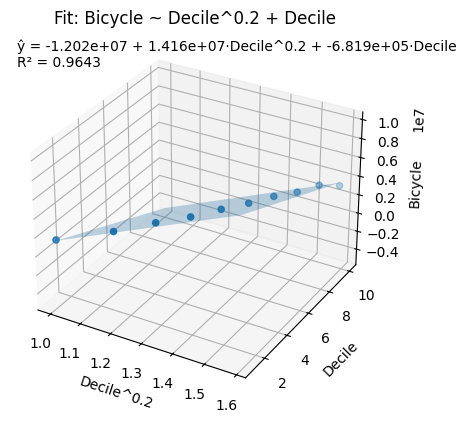

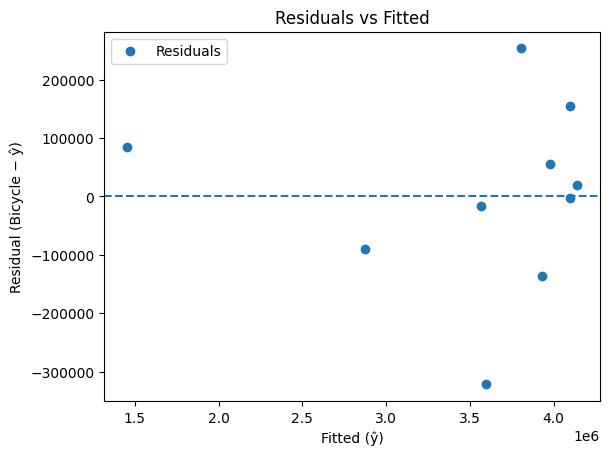

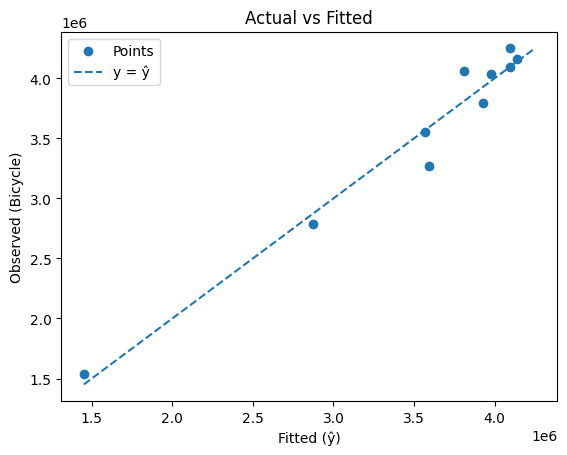

({'beta': [-12024628.183922024, 14157232.553776544, -681924.6678237738],
  'stderr': [1372973.5208270245, 1323163.974899763, 82293.74206122976],
  'tvals': [-8.758091836089358, 10.699529931540821, -8.286470523073252],
  'pvals': [5.091024156285184e-05,
   1.3676800915838614e-05,
   7.276056667300868e-05],
  'train_metrics': {'R2': 0.9643024909386563,
   'RMSE': 151599.98988169245,
   'MAE': 113623.45780792917,
   'RSS': 229825569321.29257,
   'TSS': 6438140233436.258,
   'AdjR2': 0.9541032026354153,
   'sigma2': 32832224188.75608,
   'dof': 7},
  'test_metrics': None,
  'names': ['Intercept', 'Decile^0.2', 'Decile']},
 'charts/my_fit.html')

In [84]:
# RC(agg['Motorcycle'], AD, split = (AD > 1) * (AD < 10), YN = 'Motorcycle', XsN=['Decile'])

# RC(agg['Car'], AD)
# RC(agg['000'], AD, AD**2);
RC(agg['Bicycle'], AD**0.2, AD, YN="Bicycle", XsN=["Decile^0.2", "Decile"])



In [89]:
Xs = ['Year', 'Decile', 'InCity']

agg = Agg(Xs)
AY = agg['Year'] - min(years) + 1
AD = agg['Decile']
AC = agg['InCity'].astype('int')

In [111]:
# RC(agg['Motorcycle'], AD, AC, AC*AD, AD**2*AC, split=0.2, YN = "Motorcycle", 
#    XsN = ["Decile(D)", "In City(C)", "D * C", "D^2 * C"]);


# Xs = ['Decile', 'InCity']
# agg = Agg(Xs)
# AD = agg['Decile']
# AC = agg['InCity'].astype('int')
# RC(agg['Bicycle'], AD*AC, AD**2*AC, YN="Bicycle", XsN=['Decile for urban', 'Decile^2 for urban'])

